# **MÓDULO 18 - Pratique**
# Regressão Linear

Agora que aprendemos como aplicar a regressão linear simples e múltipla, colocaremos em prática os conceitos vistos na aula.

Temos aqui uma base de imóveis para alugar, precisamos desenvolver um modelo de regressão linear múltipla para conseguir prever o preço de imóveis dadas as variáveis independentes do nosso modelo.

**Atenção! Esse é seu primeiro modelo, caso tenha dificuldade conte com a ajuda da tutoria**

Você notará que alguns códigos já estão presentes para facilitar a construção de vocês.

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [4]:
df = pd.read_csv("ALUGUEL_MOD12.csv", delimiter=';')

df.head(10)

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
0,480,295,48,2,2,1,1
1,500,0,50,1,2,1,1
2,500,0,40,1,2,1,1
3,500,36,45,1,2,1,0
4,500,0,30,1,1,0,0
5,500,380,66,2,1,0,1
6,550,100,48,2,2,1,1
7,600,110,46,2,2,1,1
8,600,100,49,2,2,1,1
9,600,325,50,2,2,1,1


Legenda dos dados:

*   **Valor_Aluguel** : valor Total pago no aluguel

*   **Valor_Condominio** : Valor do Condomínio.

*   **Metragem** : Metragem do Apartamento.

*   **N_Quartos** : Número de Quartos do Imóvel.

*   **N_banheiros** : Número de banheiros.

*   **N_Suites** : Número de Suítes.

*   **N_Vagas** : Número de Vagas.

# 1 - Realize a primeira etapa de pré processamento dos dados.

A) Verifique os tipos de dados.


B) Verifique os dados faltantes, se houver dados faltantes faça a substituição ou remoção justificando sua escolha.

In [5]:
# ==========================================
# EXERCÍCIO 1: PRÉ-PROCESSAMENTO (ETAPA 1)
# ==========================================

# A) Verificando a estrutura geral e os tipos de dados das colunas
print("--- 1.A: Tipos de Dados e Estrutura ---")
df.info()

print("\n" + "="*40 + "\n")

# B) Verificando a presença de dados faltantes (nulos) por coluna
print("--- 1.B: Contagem de Dados Faltantes ---")
dados_nulos = df.isnull().sum()
print(dados_nulos)

--- 1.A: Tipos de Dados e Estrutura ---
<class 'pandas.DataFrame'>
RangeIndex: 7203 entries, 0 to 7202
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Valor_Aluguel     7203 non-null   int64
 1   Valor_Condominio  7203 non-null   int64
 2   Metragem          7203 non-null   int64
 3   N_Quartos         7203 non-null   int64
 4   N_banheiros       7203 non-null   int64
 5   N_Suites          7203 non-null   int64
 6   N_Vagas           7203 non-null   int64
dtypes: int64(7)
memory usage: 394.0 KB


--- 1.B: Contagem de Dados Faltantes ---
Valor_Aluguel       0
Valor_Condominio    0
Metragem            0
N_Quartos           0
N_banheiros         0
N_Suites            0
N_Vagas             0
dtype: int64


### Análise da Etapa 1:

Após a verificação dos dados, constatou-se que todas as colunas possuem tipos numéricos adequados (int64) e que não existem valores nulos (faltantes) na base de dados. Dessa forma, não foi necessária a remoção ou substituição de registros nesta etapa.

# 2 - Realize a segunda etapa de pré processamento dos dados.

A) Utilize a função describe para identificarmos outliers e verificarmos a distribuição dos dados.


B) Caso note uma variável que te pareça conter outliers realiza a análise e tratamento desses dados, justificando a escolha do método utilizado.

C) Realize a análise bivariada dos dados. Faça uso de pelo menos 3 gráficos e traga insights acerca do analisado.

In [6]:
df.describe()

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
count,7203.000000,7203.000000,7203.000000,7203.000000,7203.000000,7203.000000,7203.00000
mean,2966.596140,811.538109,88.506178,2.300153,2.095932,1.016660,1.44176
std,2948.720385,796.564846,61.567505,0.826615,0.983812,0.874204,0.86993
min,480.000000,0.000000,30.000000,1.000000,1.000000,0.000000,0.00000
25%,1350.000000,395.000000,52.000000,2.000000,2.000000,1.000000,1.00000
50%,2000.000000,592.000000,67.000000,2.000000,2.000000,1.000000,1.00000
75%,3200.000000,980.000000,100.000000,3.000000,2.000000,1.000000,2.00000
max,25000.000000,9500.000000,880.000000,10.000000,8.000000,5.000000,9.00000


In [7]:

# 2. B) Identificação e tratamento de outliers utilizando a Amplitude Interquartil (IQR)

# Selecionamos as colunas numéricas contínuas para o tratamento
colunas_continuas = ['Valor_Aluguel', 'Metragem', 'Valor_Condominio']

# Criamos uma cópia da base para preservar os dados originais
df_clean = df.copy()

# Aplicação da regra do IQR para remover outliers
for coluna in colunas_continuas:
    Q1 = df_clean[coluna].quantile(0.25)
    Q3 = df_clean[coluna].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    # Mantemos apenas os dados dentro dos limites calculados
    df_clean = df_clean[(df_clean[coluna] >= limite_inferior) & (df_clean[coluna] <= limite_superior)]

print(f"Quantidade de linhas original: {len(df)}")
print(f"Quantidade de linhas após tratamento via IQR: {len(df_clean)}")

Quantidade de linhas original: 7203
Quantidade de linhas após tratamento via IQR: 5682


C:\Users\aline\AppData\Local\Temp\ipykernel_6664\1080083986.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='N_Quartos', y='Valor_Aluguel', ax=axes[1], palette='Blues')


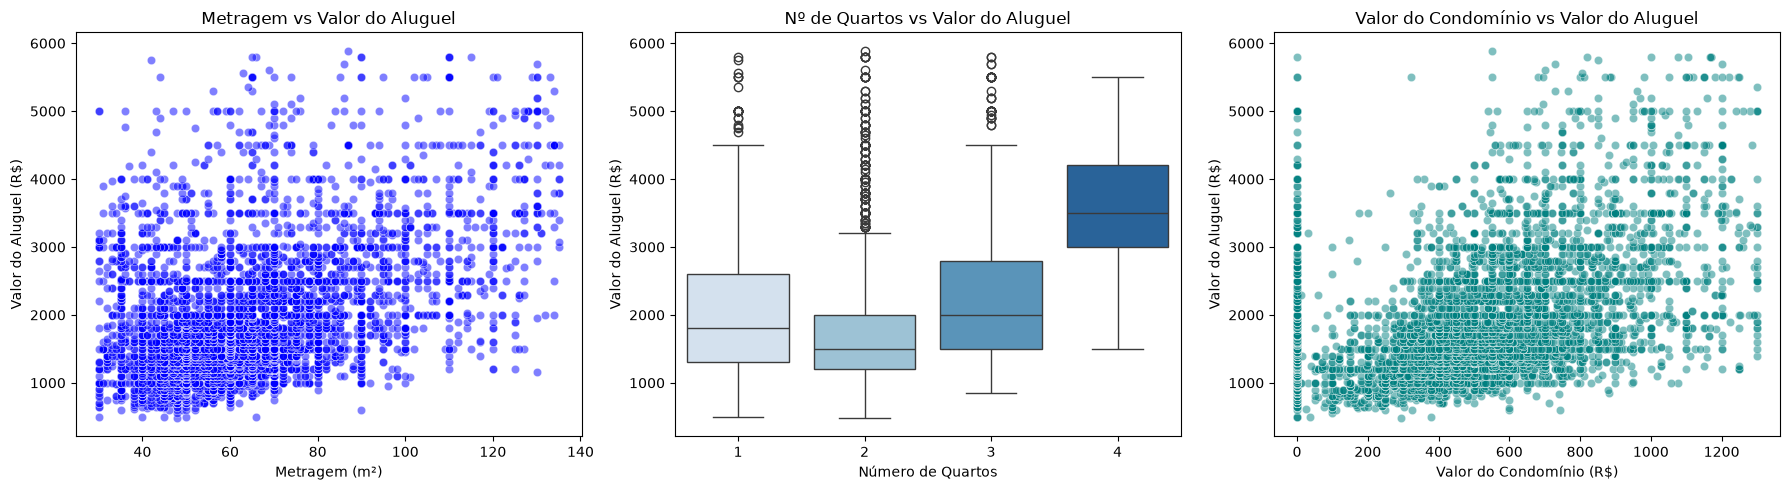

In [8]:
# 2. C) Análise Bivariada com 3 gráficos usando a base tratada (df_clean)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Metragem vs Valor_Aluguel
sns.scatterplot(data=df_clean, x='Metragem', y='Valor_Aluguel', ax=axes[0], alpha=0.5, color='blue')
axes[0].set_title('Metragem vs Valor do Aluguel')
axes[0].set_xlabel('Metragem (m²)')
axes[0].set_ylabel('Valor do Aluguel (R$)')

# Gráfico 2: N_Quartos vs Valor_Aluguel
sns.boxplot(data=df_clean, x='N_Quartos', y='Valor_Aluguel', ax=axes[1], palette='Blues')
axes[1].set_title('Nº de Quartos vs Valor do Aluguel')
axes[1].set_xlabel('Número de Quartos')
axes[1].set_ylabel('Valor do Aluguel (R$)')

# Gráfico 3: Valor_Condominio vs Valor_Aluguel
sns.scatterplot(data=df_clean, x='Valor_Condominio', y='Valor_Aluguel', ax=axes[2], alpha=0.5, color='teal')
axes[2].set_title('Valor do Condomínio vs Valor do Aluguel')
axes[2].set_xlabel('Valor do Condomínio (R$)')
axes[2].set_ylabel('Valor do Aluguel (R$)')

plt.tight_layout()
plt.show()

Análise do Item 2.A:

Através da função df.describe(), identificou-se a presença de outliers principalmente nas variáveis Valor_Aluguel, Metragem e Valor_Condominio. Em todas elas, os valores máximos estão extremamente distantes do 3º quartil (75%) e a média está visivelmente deslocada para cima em relação à mediana. Por exemplo, no Valor_Aluguel, a mediana é de R$ 2.000,00, enquanto o valor máximo atinge R$ 25.000,00.

Análise do Item 2.B

Justificativa do Método Utilizado:Optou-se pela utilização do método da Amplitude Interquartil (IQR) por ser uma métrica estatística robusta e formal. Ao contrário da remoção visual ou arbitrária, o IQR utiliza os quartis da distribuição ($Q1$ e $Q3$) para delimitar numericamente os limites superior e inferior de aceitação, garantindo a eliminação de outliers sem introduzir viés manual na base de dados. 

Análise do Item 2.C

1. Metragem vs. Valor do Aluguel
Observa-se uma relação positiva entre a metragem e o valor do aluguel: quanto maior o imóvel, maior tende a ser o preço. Contudo, nota-se uma dispersão onde imóveis de metragem reduzida apresentam aluguéis elevados, indicando a influência de outros fatores, como localização ou padrão do imóvel.

2. Nº de Quartos vs. Valor do Aluguel
Há uma tendência de elevação no valor mediano do aluguel conforme o número de quartos aumenta. No entanto, o gráfico de boxplot evidencia a presença de valores superiores discrepantes (outliers locais), mostrando que imóveis de 1 quarto podem atingir valores superiores a imóveis com 2 ou mais quartos.
Curiosamente, a mediana do valor do aluguel para imóveis de 1 quarto (R$ 1.800,00) é superior à dos imóveis de 2 quartos (R$ 1.500,00). Isso reflete uma dinâmica de mercado onde imóveis de 1 quarto (como studios e lofts modernos em localizações nobres) possuem alto valor agregado por m², enquanto a categoria de 2 quartos concentra um volume maior de imóveis padrão ou mais antigos. A partir de 3 quartos, o valor mediano volta a subir progressivamente.

3. Valor do Condomínio vs. Valor do Aluguel
Nota-se uma concentração significativa de registros com valor de condomínio zerado (imóveis de rua ou sem taxa). Para os demais dados, observa-se uma tendência positiva, onde condomínios de valor mais elevado acompanham aluguéis mais caros.

# 3 - Realize a terceira etapa de pré processamento dos dados.

A) Comece pela correlação, que sabemos ser uma parte importante para nosso pré processamento e análise. Plote o gráfico ou a tabela e indique as variáveis que te parecem mais "fortes" na correlação para nosso modelo.




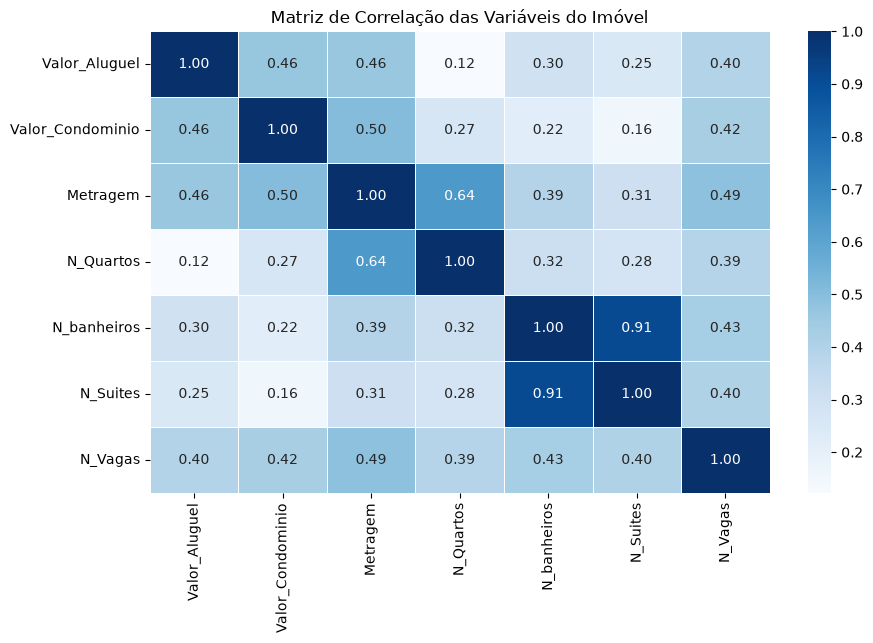

--- Correlação em relação ao Valor_Aluguel ---
Valor_Aluguel       1.000000
Valor_Condominio    0.464906
Metragem            0.462202
N_Vagas             0.395527
N_banheiros         0.298106
N_Suites            0.254363
N_Quartos           0.121683
Name: Valor_Aluguel, dtype: float64


In [9]:
# 3. A) Matriz de correlação e mapa de calor (heatmap)
plt.figure(figsize=(10, 6))

# Calculando a correlação de Pearson entre as variáveis
matriz_correlacao = df_clean.corr()

# Plotando o mapa de calor
sns.heatmap(matriz_correlacao, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlação das Variáveis do Imóvel')
plt.show()

# Exibindo a correlação direta de todas as variáveis em relação ao Valor_Aluguel
print("--- Correlação em relação ao Valor_Aluguel ---")
print(matriz_correlacao['Valor_Aluguel'].sort_values(ascending=False))

Análise do Item 3.A:

Ao analisar a matriz de correlação em relação à variável dependente Valor_Aluguel, observa-se que as variáveis explicativas mais fortes são Valor_Condominio (0,46), Metragem (0,46) e N_Vagas (0,40). Nenhuma variável individual apresenta correlação forte (acima de 0,50), o que justifica o uso de um modelo de regressão múltipla.

Por outro lado, a variável que apresentou a correlação linear mais fraca com o preço do aluguel foi N_Quartos (0,12)


B) Durante a aula, por nossa base ser pequena e demonstrativa não realizamos a separação de treino e teste, porém para as atividades do dia dia temos que fazer, nesse exercício separe treino e teste.

Lembre-se que primeiro separamos as variaveis dependentes X e depois Y, essa etapa deixarei para vocês abaixo:

In [10]:
X = df.drop('Valor_Aluguel', axis=1) #Separando X - Todas variáveis exceto valor_aluguel
y = df['Valor_Aluguel'] #Separando Y (Apenas variavel valor_aluguel)

Dica: Para separar em treino e teste usamos o train_test_split, como visto nas aulas de pré modelagem.

In [11]:
# Divisão dos dados em conjunto de treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Exibindo o tamanho de cada conjunto
print(f"Total de linhas na base tratada: {len(df_clean)}")
print(f"Linhas para Treino (X_train): {len(X_train)}")
print(f"Linhas para Teste (X_test): {len(X_test)}")

Total de linhas na base tratada: 5682
Linhas para Treino (X_train): 5762
Linhas para Teste (X_test): 1441


# 3 - Treine um modelo de regressão Linear simples

A) Vamos utilizar apenas X_train e y_train para rodar um modelo de regressão linea simples e para isso usaremos apenas uma váriavel, a váriavel metragem.

In [12]:
X = X_train[['Metragem']]  # Variável independente (características)
y = y_train  # Variável dependente (rótulo)
# se você deu um nome diferente para x train e y train, altere no código.

In [17]:
# 3. A) Selecionando apenas a variável 'Metragem' para o modelo simples (usando os dados de treino)
X_train_simples = X_train[['Metragem']]
X_test_simples = X_test[['Metragem']]

# Criando e treinando o modelo de Regressão Linear Simples
modelo_simples = LinearRegression()
modelo_simples.fit(X_train_simples, y_train)

# 3. B) Extraindo o Intercepto e o Coeficiente angular
intercepto = modelo_simples.intercept_
coeficiente = modelo_simples.coef_[0]

print(f"Intercepto (a): {intercepto:.2f}")
print(f"Coeficiente Angular (b): {coeficiente:.2f}")
print(f"\nEquação da reta: Valor_Aluguel = {intercepto:.2f} + ({coeficiente:.2f} * Metragem)")


Intercepto (a): -97.00
Coeficiente Angular (b): 34.47

Equação da reta: Valor_Aluguel = -97.00 + (34.47 * Metragem)


B) Plote o intercept_ e coef_ e monte de forma extensa a equação da reta.

In [ ]:
#Seu código Aqui

Nossa equação seria:  

c) Calcule o R quadrado para o modelo de treinamento. Não esqueça de avaliar e trazer em formato de insight se esse resultado te parece bom ou não.

In [19]:
# 3. C) Calculando o R² para o modelo de treino simples
r2_treino = modelo_simples.score(X_train_simples, y_train)

print(f"Coeficiente de Determinação (R²) nos Dados de Treino: {r2_treino:.4f}")

Coeficiente de Determinação (R²) nos Dados de Treino: 0.5214


D) Plote o gráfico da reta de regressão encontrada e traga insights acerca da dispersão dos pontos e ajuste da reta.

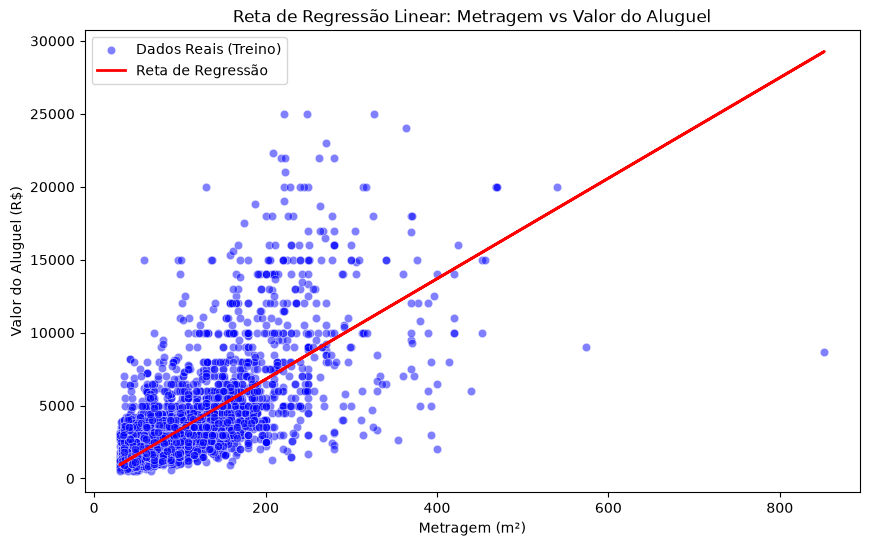

In [21]:
# 3. D) Plotando o gráfico da reta de regressão simples
plt.figure(figsize=(10, 6))

# Pontos reais dos dados de treino
sns.scatterplot(x=X_train_simples['Metragem'], y=y_train, color='blue', alpha=0.5, label='Dados Reais (Treino)')

# Reta de regressão ajustada pelo modelo simples
plt.plot(X_train_simples['Metragem'], modelo_simples.predict(X_train_simples), color='red', linewidth=2, label='Reta de Regressão')

plt.title('Reta de Regressão Linear: Metragem vs Valor do Aluguel')
plt.xlabel('Metragem (m²)')
plt.ylabel('Valor do Aluguel (R$)')
plt.legend()
plt.show()

Insights sobre a dispersão dos pontos e o ajuste da reta:

Tendência Principal: A reta vermelha reflete uma inclinação positiva, mostrando que imóveis maiores possuem estimativas de aluguel mais elevadas. 

Dispersão dos Pontos: Nota-se que os pontos estão bastante concentrados nas metragens menores (até 150 m²), mas à medida que a metragem aumenta, a variação de preços torna-se muito maior.   

Presença de Pontos Distantes (Outliers): Existem imóveis com metragens médias cujos preços estão muito distantes da reta vermelha. Isso reforça graficamente que apenas a metragem não consegue capturar todos os fatores de preço, justificando o uso da regressão múltipla.  

E) Para finalizar vamos aplicar o modelo a base de teste. Essa etapa é nova, então agora vocês avaliaram como o modelo treinado se saiu com a base de testes.
Para isso altere no código abaixo o nome do seu modelo de regressão:

In [22]:
X_test = X_test[['Metragem']]  # Variável independente (características)
y_test = y_test  # Variável dependente (rótulo)

In [23]:
# 3. E) Aplicando o modelo de regressão simples aos dados de teste
X_test_simples = X_test[['Metragem']]  # Variável independente (características)
y_test = y_test  # Variável dependente (rótulo)

# Usando o modelo treinado para fazer previsões sobre os dados de teste
previsoes = modelo_simples.predict(X_test_simples)

# Avaliando o desempenho do modelo usando a métrica R²
r2_teste = modelo_simples.score(X_test_simples, y_test)

print("Coeficiente de Determinação (R²) nos Dados de Teste:", r2_teste)


Coeficiente de Determinação (R²) nos Dados de Teste: 0.5697993791211697


Se o valor do coeficiente de determinação (R²) para os dados de treinamento for melhor (ou seja, mais próximo de 1) do que o R² para os dados de teste, isso sugere que o modelo está superajustado aos dados de treinamento. Isso significa que o modelo pode estar se ajustando muito bem aos padrões específicos nos dados de treinamento, mas pode não generalizar bem para novos dados que não foram vistos durante o treinamento.

Por outro lado, se o R² para os dados de teste for melhor do que o R² para os dados de treinamento, isso pode ser indicativo de que o modelo está subajustado. Isso significa que o modelo não está se ajustando adequadamente aos padrões nos dados de treinamento e não está capturando a relação entre as variáveis independentes e dependentes de forma eficaz.

Idealmente, gostaríamos que o valor do R² fosse consistente entre os dados de treinamento e teste, indicando que o modelo é capaz de generalizar bem para novos dados. Se houver uma grande diferença entre os valores de R² para os dados de treinamento e teste, isso sugere que o modelo pode precisar de ajustes para melhorar sua capacidade de generalização.

F) Avalie com suas palavras o valor do r quadrado encontrado no treino e no teste.

O modelo de Regressão Linear Simples apresentou um R² de 0,5214 (52,14%) nos dados de treino e de 0,5698 (56,98%) nos dados de teste.   

Conclusão: Os valores de R² apresentaram-se muito consistentes e equilibrados entre as duas etapas, demonstrando que o modelo possui uma boa capacidade de generalização e não sofreu de overfitting. A pequena variação indica estabilidade nas previsões para dados inéditos, porém o teto de explicação de aproximadamente 57% reforça a necessidade de evoluir para um modelo de regressão múltipla

# 4 - Aplicação do modelo de regressão linear multipla!

A) Vamos refazer os passos anteriores porém para regressão multipla, com todas variáveis dependentes. Comece separando a base treino e teste, dessa vez com todas variáveis para X.

Aqui é só refazer os passos do exercicio 3 porém ao invés de trazer para X apenas metragem, você deve trazer todas colunas (exceto a valor do aluguel).

In [24]:
# 4. A) Separando X (todas as variáveis explicativas) e y (variável alvo)
X = df.drop('Valor_Aluguel', axis=1) # Todas as colunas exceto Valor_Aluguel
y = df['Valor_Aluguel']              # Apenas o Valor_Aluguel

# Separação em dados de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

print("Separação de treino e teste realizada com todas as variáveis!")

Separação de treino e teste realizada com todas as variáveis!


B) Faça o modelo de regressão linear multipla aplicado só a base de treino.

In [25]:
# 4. B) Criando e treinando o modelo de regressão linear múltipla na base de treino
modelo_multiplo = LinearRegression()
modelo_multiplo.fit(X_train, y_train)

print("Modelo de Regressão Linear Múltipla treinado com sucesso!")

Modelo de Regressão Linear Múltipla treinado com sucesso!


C) Traga o valor do R quadrado e avalie o valor encontrado.

In [26]:
# 4. C) Calculando o R² do modelo múltiplo nos dados de treino
r2_multiplo_treino = modelo_multiplo.score(X_train, y_train)

print(f"R² nos dados de treino (Regressão Múltipla): {r2_multiplo_treino:.4f}")

R² nos dados de treino (Regressão Múltipla): 0.5972


D) Para finalizar aplique o modelo a base de teste e traga o r quadrado de teste.
Dica: Você pode usar os códigos do exercício anterior.

In [27]:
# 4. D) Calculando o R² do modelo múltiplo nos dados de teste
r2_multiplo_teste = modelo_multiplo.score(X_test, y_test)

print(f"R² nos dados de teste (Regressão Múltipla): {r2_multiplo_teste:.4f}")

R² nos dados de teste (Regressão Múltipla): 0.6328


E) Compare os r quadrados encontrados pela regressão linear e pela regressão múltipla. Qual modelo te parece melhor? Por qual motivo acredita que isso ocorreu?

O modelo de Regressão Linear Múltipla superou a Regressão Linear Simples, elevando o Coeficiente de Determinação ($R^2$) de $56,98\%$ para $63,28\%$ nos dados de teste.

Conclusão: A inclusão das demais variáveis explicativas (como valor do condomínio, número de vagas e banheiros) permitiu capturar de forma mais abrangente a precificação do mercado imobiliário, reduzindo o erro do modelo e melhorando a sua capacidade de generalização para novos dados.  